## Figures

## Setup

In [13]:
import random
from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import importlib
import src.utils as ut
importlib.reload(ut)

# Same paths as N2_bc_loop_complete_dataset.ipynb (run from the repo root)
paths_results_data = Path("data/processed")
paths_datasets = Path("/Users/rashid/data/DS/Healthcare/Breast/CHSJ/BreastCancer_Benign")

metrics_csv = paths_results_data / "metrics" / "edge_metrics.csv"
out_dir = paths_results_data / "graphs"
out_dir.mkdir(parents=True, exist_ok=True)

save_params = dict(dpi=300, transparent=True, bbox_inches="tight")

def save_figure(fig, name):
    """Save a figure as png, pdf and svg in the graphs folder."""
    for ext in ("png", "pdf", "svg"):
        fig.savefig(out_dir / f"{name}.{ext}", **save_params)

/Users/rashid/miniconda3/envs/VHT/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Figure 2
Sample images from the CHSJ dataset.

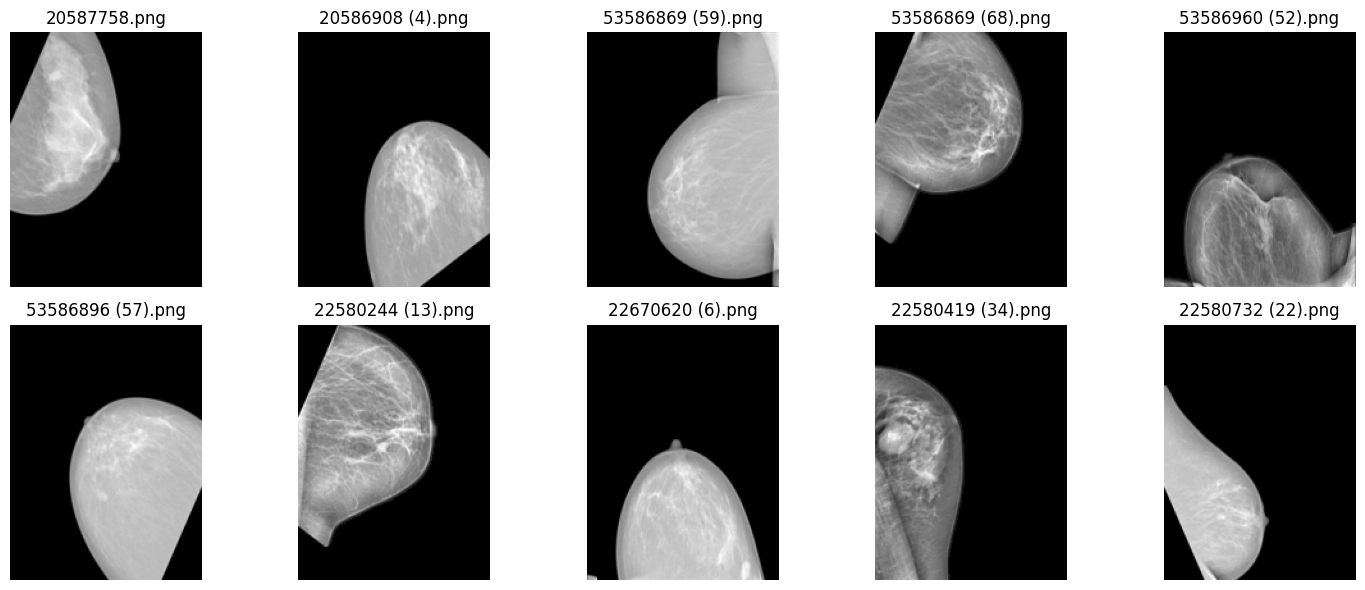

In [11]:
# Get all image files from the dataset folder
all_images = [f for f in sorted(paths_datasets.iterdir())
              if f.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tiff"}]

# Randomly pick 10 images
random_images = random.sample(all_images, 10)

# Plot images in 2x5 grid
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, img_path in zip(axes.flat, random_images):
    # Same preprocessing as N1/N2: resize (150x200) -> grayscale -> background removal
    _, bg_removed, mask = ut.fun_load_preprocessed(img_path)
    ax.imshow(bg_removed, cmap="gray")
    ax.set_title(img_path.name, fontsize=12)
    ax.axis("off")

plt.tight_layout()
save_figure(fig, "Sample images from CHSJ Dataset")
plt.show()

## Figure No 3

## Figure No 4

## Figure-9

Saving results to: data/processed/vht/


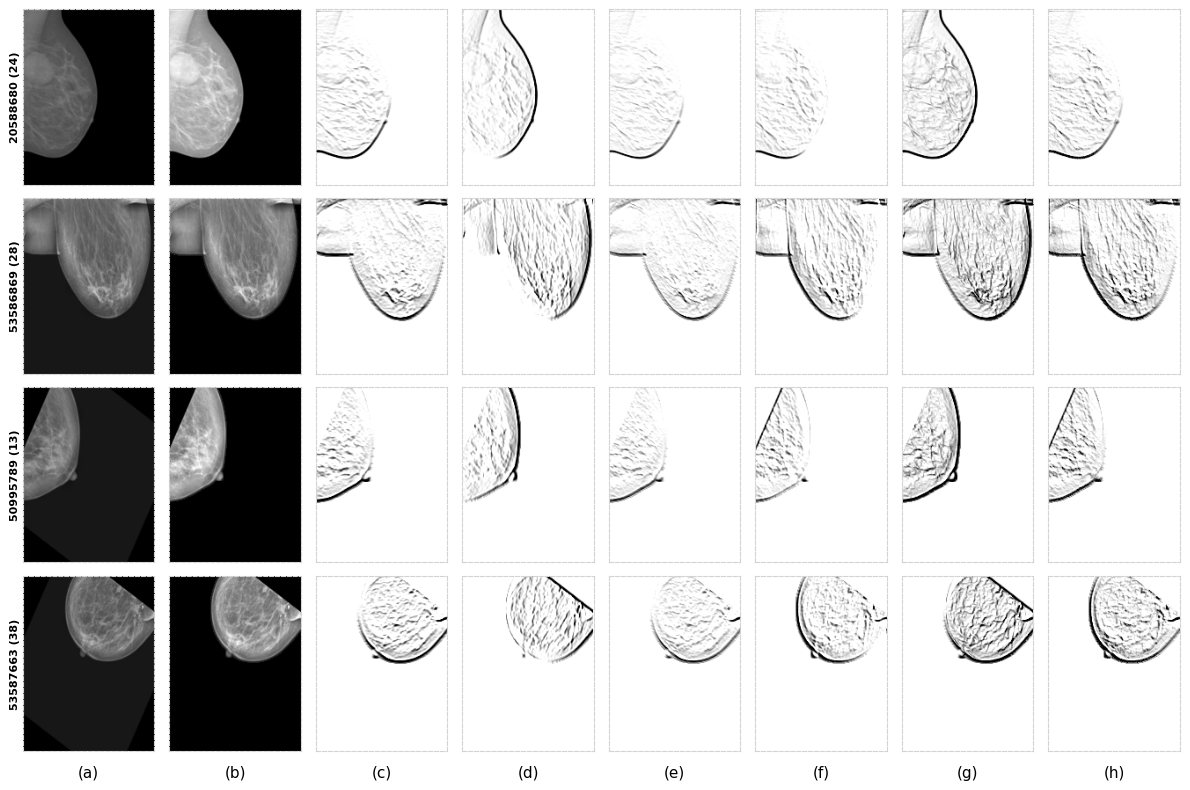

In [16]:
# Input & Output folders
input_folder = paths_datasets #r"C:/programming/pythonML/computerVision/Breast_cancer/datasets"
output_folder = f"{paths_results_data}/vht/"
output_combined = f"{paths_results_data}/combined/"
os.makedirs(output_folder, exist_ok=True)

print("Saving results to:", output_folder)

# Collect image files
image_files = [f for f in os.listdir(input_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif'))]
if not image_files:
    raise FileNotFoundError(f"No images found in folder: {input_folder}")


# --- Plot Grid (just first few for visualization) ---
cols = 8
rows = min(4, len(all_results))  # show max 4 images in grid
fig, axes = plt.subplots(rows, cols, figsize=(12, rows * 2))

# col_titles = ["Original", "Gray", "X-axis", "Y-axis", "Diag", "Anti-Diag", "Combined_xy", "Combined_yx"]

for r in range(rows):
    for c in range(cols):
        ax = axes[r, c] if rows > 1 else axes[c]
        if c == 0:
            ax.imshow(all_results[r][c])  # RGB color for original
        else:
            ax.imshow(all_results[r][c], cmap='gray')
        ax.set_xticks([]), ax.set_yticks([])
       
        # Light gray dashed axes
        for spine in ax.spines.values():
            spine.set_edgecolor("lightgray")
            spine.set_linestyle("--")
            spine.set_linewidth(0.8)
            
        # if r == 0:
        #     ax.set_title(col_titles[c], fontsize=9, pad=2)
        if c == 0:
            ax.set_ylabel(image_files[r], fontsize=8, rotation=90, labelpad=2, weight='bold')
            
        import string
labels = [f"({ch})" for ch in string.ascii_lowercase]

for r in range(rows):
    for c in range(cols):
        ax = axes[r, c] if rows > 1 else axes[c]

        # ✅ remove extension before using as ylabel
        if c == 0:
            # get filename without extension
            name_without_ext = os.path.splitext(image_files[r])[0]
            ax.set_ylabel(name_without_ext,
                          fontsize=8, rotation=90, labelpad=2, weight='bold')

        # ✅ Only add (a), (b), … under the last row
        if r == rows - 1:
            ax.set_xlabel(labels[c], fontsize=11, labelpad=10)


plt.tight_layout()
# Save the figure all in graphs folder
out_dir = f"{paths_results_data}/graphs"
os.makedirs(out_dir, exist_ok=True)

save_params = dict(dpi=300, transparent=True, bbox_inches='tight')
for ext in ["png", "pdf", "svg"]:
    plt.savefig(os.path.join(out_dir, f"Proposed NIVHT All Variations.{ext}"), **save_params)
plt.show()

## Load metrics
Reads `data/processed/metrics/edge_metrics.csv`, written by the metrics cell in `N2_bc_loop_complete_dataset.ipynb`.

In [3]:
if not metrics_csv.exists():
    raise FileNotFoundError(
        f"{metrics_csv} not found. Run the metrics cell in "
        "N2_bc_loop_complete_dataset.ipynb first."
    )

metrics_df = pd.read_csv(metrics_csv)

# Edge detectors in plotting order. "Original" is the reference image, not a method.
method_order = ["Roberts", "Sobel", "Canny", "Prewitt", "Laplacian", "Proposed"]
method_names = {"Proposed": "Proposed NIVHT"}
labels = [method_names.get(m, m) for m in method_order]

comparison_df = (
    metrics_df[metrics_df["Method"].isin(method_order)]
    .replace([np.inf, -np.inf], np.nan)  # PSNR can be inf
)

# Per-method mean and std over all images
summary = (
    comparison_df.drop(columns="Image")
    .groupby("Method")
    .agg(["mean", "std"])
    .reindex(method_order)
)

x = np.arange(len(method_order))
print(f"Loaded {len(metrics_df)} rows for {metrics_df['Image'].nunique()} images from {metrics_csv}")
display(summary.round(3))

Loaded 350 rows for 50 images from data/processed/metrics/edge_metrics.csv


Number_of_Edges           Edge_Density           EPI        Entropy  \
                     mean       std         mean    std   mean    std    mean   
Method                                                                          
Roberts           4760.22  2191.715        0.159  0.073  0.512  0.031   0.259   
Sobel             5235.04  2369.478        0.175  0.079  0.371  0.046   0.238   
Canny             3323.68   614.857        0.111  0.020  0.501  0.055   0.302   
Prewitt           5150.46  2362.074        0.172  0.079  0.362  0.043   0.235   
Laplacian         6405.34  1996.753        0.214  0.067  0.361  0.028   0.291   
Proposed          1682.78   246.687        0.056  0.008  0.562  0.068   0.198   

                    PSNR         ... Avg_Edge_Length         Max_Edge_Length  \
             std    mean    std  ...            mean     std            mean   
Method                           ...                                           
Roberts    0.063  18.155  2.804  ...          58.894  15.671         109.261   
Sobel      0.051  18.321  2.816  ...          60.226  16.389         111.323   
Canny      0.046  10.166  0.858  ...          54.222   9.099         112.756   
Prewitt    0.053  18.311  2.832  ...          60.247  15.619         111.527   
Laplacian  0.022  16.769  3.068  ...          71.833  20.316         129.406   
Proposed   0.028  12.828  0.876  ...          13.052  27.117          14.237   

                  Min_Edge_Length         Hough_Segments          \
              std            mean     std           mean     std   
Method                                                             
Roberts    31.040          12.517  15.094          54.88  39.991   
Sobel      30.249          11.541  12.744          60.66  37.385   
Canny      22.293          12.085   7.535          28.20  15.277   
Prewitt    31.179          11.881  12.942          60.18  39.237   
Laplacian  18.741           9.723   8.162          72.14  21.065   
Proposed   29.144          11.533  25.680           0.36   0.776   

          Connected_Components          
                          mean     std  
Method                                  
Roberts                  73.50  44.298  
Sobel                    61.28  35.935  
Canny                   133.46  44.240  
Prewitt                  68.76  36.881  
Laplacian                94.80  89.245  
Proposed                339.26  94.151  

[6 rows x 24 columns]

## Figure-13: Number of detected edges

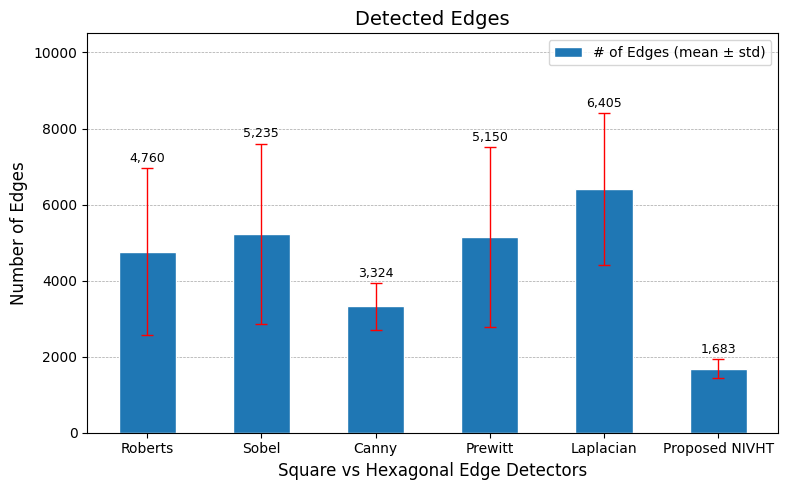

In [4]:
edges = summary[("Number_of_Edges", "mean")].to_numpy()
errors = summary[("Number_of_Edges", "std")].fillna(0).to_numpy()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(x, edges, width=0.5, color="tab:blue", edgecolor="white", label="# of Edges (mean ± std)",
              yerr=errors, capsize=4, error_kw={"elinewidth": 1, "ecolor": "red"})

ax.yaxis.grid(True, linestyle="--", linewidth=0.5, color="gray", alpha=0.7)
ax.set_axisbelow(True)

# Mean values above the error bars
offset = np.nanmax(edges + errors) * 0.01
for bar, value, err in zip(bars, edges, errors):
    ax.text(bar.get_x() + bar.get_width() / 2, value + err + offset, f"{value:,.0f}",
            ha="center", va="bottom", fontsize=9, color="black")

ax.set_title("Detected Edges", fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylabel("Number of Edges", fontsize=12)
ax.set_xlabel("Square vs Hexagonal Edge Detectors", fontsize=12)
ax.set_ylim(0, np.nanmax(edges + errors) * 1.25)
ax.legend()
plt.tight_layout()

save_figure(fig, "Number of edge detected")
plt.show()

## Figure-14: EPI

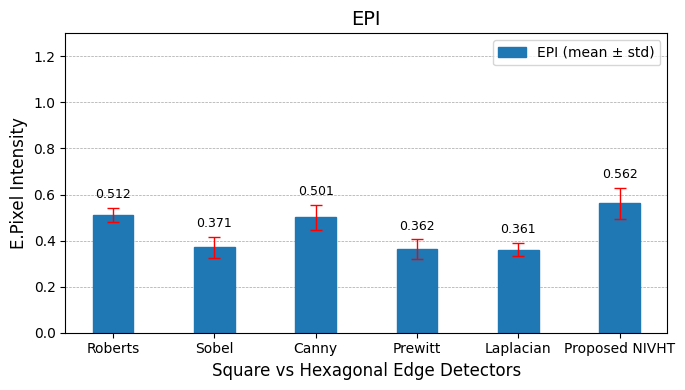

In [5]:
epi_values = summary[("EPI", "mean")].to_numpy()
epi_std = summary[("EPI", "std")].fillna(0).to_numpy()

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(x, epi_values, width=0.4, color="tab:blue", edgecolor="tab:blue", label="EPI (mean ± std)",
              yerr=epi_std, capsize=4, error_kw={"elinewidth": 1, "ecolor": "red"})

# Mean values above the error bars
for bar, value, err in zip(bars, epi_values, epi_std):
    ax.text(bar.get_x() + bar.get_width() / 2, value + err + 0.03, f"{value:.3f}",
            ha="center", va="bottom", fontsize=9, color="black")

ax.yaxis.grid(True, linestyle="--", linewidth=0.5, color="gray", alpha=0.7)
ax.set_axisbelow(True)

ax.set_title("EPI", fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylabel("E.Pixel Intensity", fontsize=12)
ax.set_xlabel("Square vs Hexagonal Edge Detectors", fontsize=12)
ax.set_ylim(0, max(1.0, np.nanmax(epi_values + epi_std)) * 1.3)
ax.legend()
plt.tight_layout()

save_figure(fig, "EPI_graph")
plt.show()

## Figure-15: Entropy vs connected edges

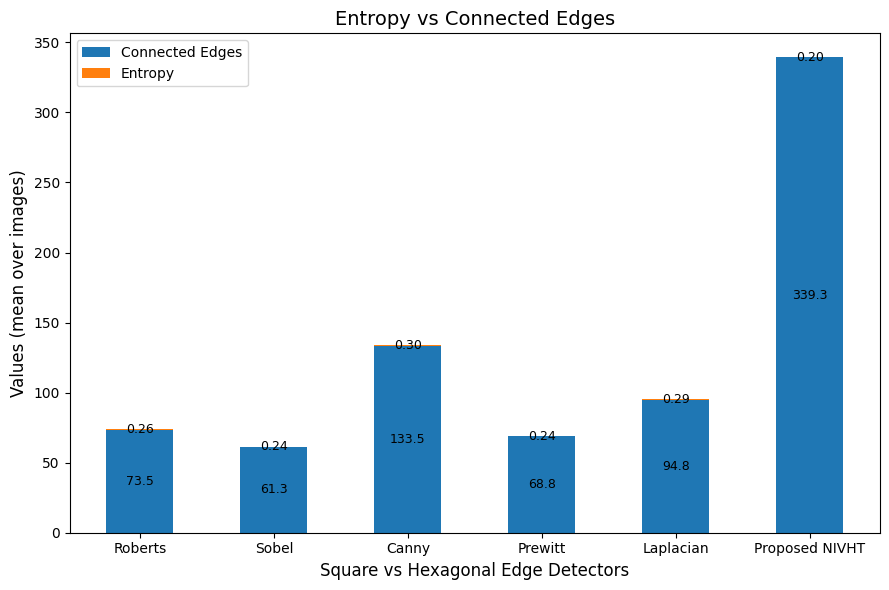

In [6]:
connected_edges = summary[("Connected_Components", "mean")].to_numpy()
entropy_vals = summary[("Entropy", "mean")].to_numpy()

fig, ax = plt.subplots(figsize=(9, 6))
width = 0.5

# Stacked bars: connected components at the bottom, entropy on top
ax.bar(x, connected_edges, width=width, label="Connected Edges", color="tab:blue")
ax.bar(x, entropy_vals, width=width, bottom=connected_edges, label="Entropy", color="tab:orange")

for i in range(len(method_order)):
    ax.text(x[i], connected_edges[i] / 2, f"{connected_edges[i]:.1f}",
            ha="center", va="center", color="black", fontsize=9)
    ax.text(x[i], connected_edges[i] + entropy_vals[i] / 2, f"{entropy_vals[i]:.2f}",
            ha="center", va="center", color="black", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylabel("Values (mean over images)", fontsize=12)
ax.set_xlabel("Square vs Hexagonal Edge Detectors", fontsize=12)
ax.set_title("Entropy vs Connected Edges", fontsize=14)
ax.legend()
plt.tight_layout()

save_figure(fig, "Entropy Vs Connected Edges")
plt.show()